In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures



from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')


In [27]:
df = pd.read_csv('Walmart_Dataset.csv', encoding='latin-1')

print(df.shape)
df.head()


(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/08/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,06/12/2016,06/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


# Data Cleaning

In [28]:
print('Column Names and Data Types:')
print(df.dtypes)

Column Names and Data Types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [29]:
print('Missing values per column:')
missing = df.isnull().sum()
print(missing[missing > 0])
print()



Missing values per column:
Ship Mode    23
Discount     49
dtype: int64



In [30]:
ship_mode_fill = df['Ship Mode'].mode()[0]
df['Ship Mode'].fillna(ship_mode_fill, inplace=False)
print(f"Filled 'Ship Mode' NaNs with mode: '{ship_mode_fill}'")

discount_fill = df['Discount'].median()
df['Discount'].fillna(discount_fill, inplace=False)
print(f"Filled 'Discount' NaNs with median: {discount_fill}")

print()
print('Missing values after cleaning:', df.isnull().sum().sum())

Filled 'Ship Mode' NaNs with mode: 'Standard Class'
Filled 'Discount' NaNs with median: 0.2

Missing values after cleaning: 72


In [31]:
dups = df.duplicated().sum()
print(f'Duplicate rows: {dups}')
if dups > 0:
    df.drop_duplicates(inplace=True)
    print(f'Removed {dups} duplicate rows.')
else:
    print('No duplicates found ')

Duplicate rows: 0
No duplicates found 


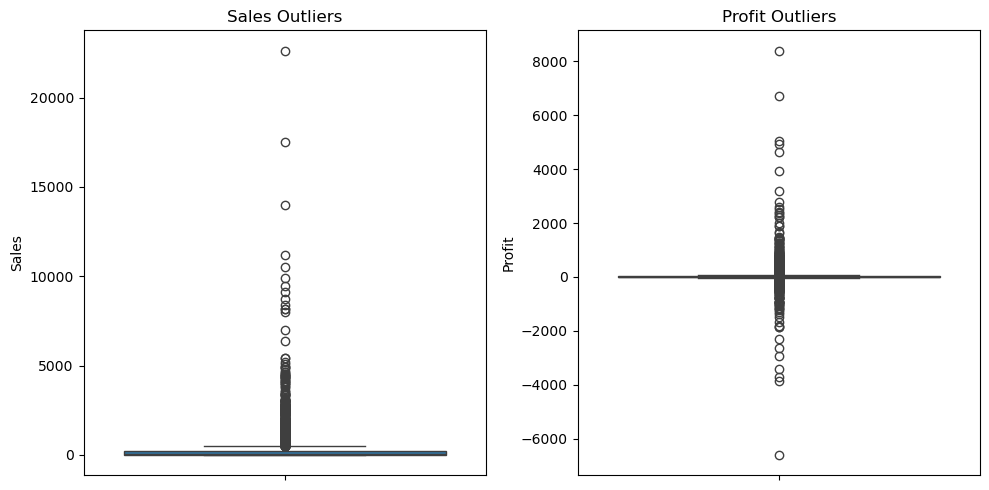

In [32]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Sales'])
plt.title('Sales Outliers')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Profit'])
plt.title('Profit Outliers')
plt.tight_layout()
plt.show()

In [33]:

for col in ['Sales', 'Profit']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    print(f"Number of Outliers in {col}: {outliers_count}")


Number of Outliers in Sales: 1167
Number of Outliers in Profit: 1881


In [34]:

for col in ['Sales', 'Profit']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower_bound, upper_bound)



# EDA and Visualization

In [35]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Month_Year'] = df['Order Date'].dt.to_period('M').astype(str)

In [36]:
df.describe().round(2)

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Year,Month
count,9994.00,9994,9994,9994.00,9994.00,9994.00,9945.00,9994.00,9994.00,9994.00
mean,4997.50,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.38,140.28,3.79,0.16,16.07,2015.72,7.81
min,1.00,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.00,0.44,1.00,0.00,-39.72,2014.00,1.00
25%,2499.25,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.00,17.28,2.00,0.00,1.73,2015.00,5.00
50%,4997.50,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.50,54.49,3.00,0.20,8.67,2016.00,9.00
75%,7495.75,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.00,209.94,5.00,0.20,29.36,2017.00,11.00
max,9994.00,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.00,498.93,14.00,0.80,70.82,2017.00,12.00
std,2885.16,NaN,NaN,32063.69,168.80,2.23,0.21,29.49,1.12,3.28


In [37]:
print('Categorical Column Value Counts')
print()
for col in ['Category', 'Sub-Category', 'Segment', 'Region', 'Ship Mode']:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

Categorical Column Value Counts

--- Category ---
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

--- Sub-Category ---
Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64

--- Segment ---
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

--- Region ---
Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

--- Ship Mode ---
Ship Mode
Standard Class    5945
Second Class      1945
First Class       1538
Same Day           543
NaN                 23
Name: count, dtype: int64



In [38]:
print(f'Date Range:')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  format='%m/%d/%Y')
print(f"  Earliest Order: {df['Order Date'].min().date()}")
print(f"  Latest  Order : {df['Order Date'].max().date()}")



Date Range:
  Earliest Order: 2014-01-03
  Latest  Order : 2017-12-30


In [39]:
print(f'Total Sales  : ${df["Sales"].sum():,.2f}')
print(f'Total Profit : ${df["Profit"].sum():,.2f}')

Total Sales  : $1,401,969.37
Total Profit : $160,583.73


<Figure size 1000x600 with 0 Axes>

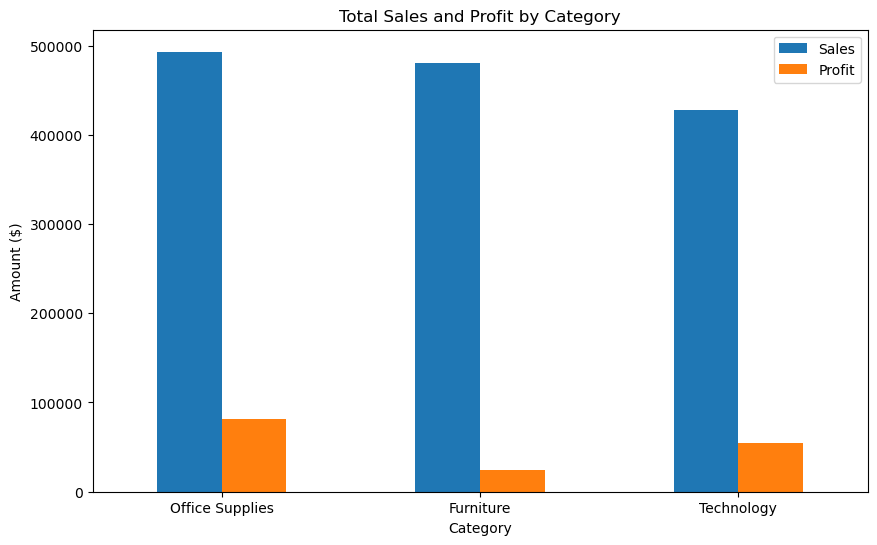

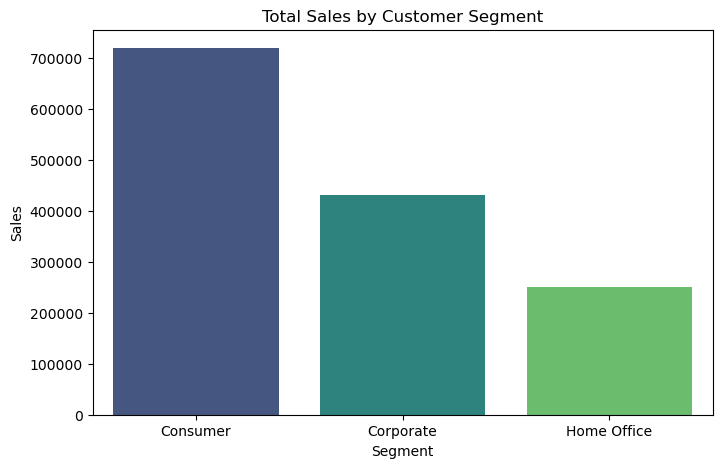

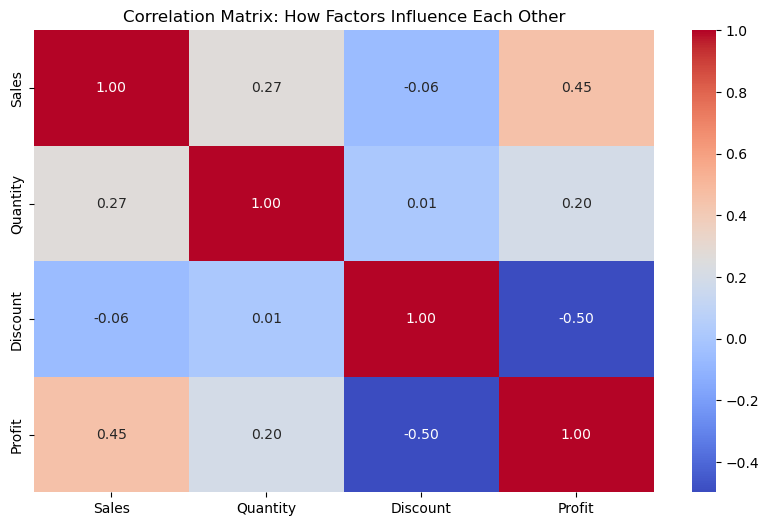

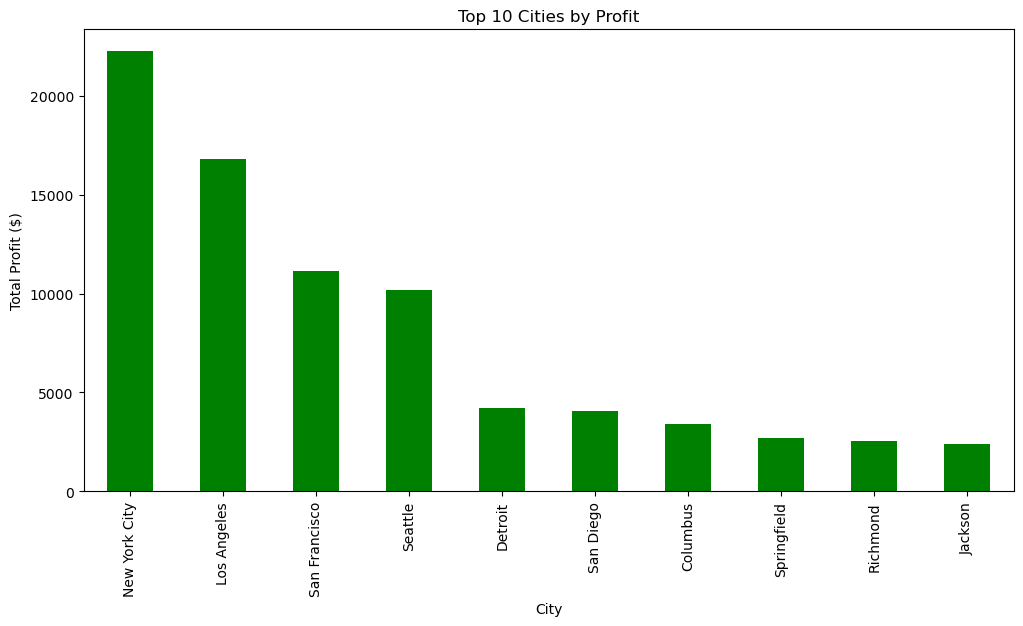

In [40]:
# (1) Sales & Profit by Category
plt.figure(figsize=(10, 6))
category_analysis = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)
category_analysis.plot(kind='bar', figsize=(10, 6), color=['#1f77b4', '#ff7f0e'])
plt.title('Total Sales and Profit by Category')
plt.ylabel('Amount ($)')
plt.xticks(rotation=0)
plt.show()

# (2) Sales by Segment
plt.figure(figsize=(8, 5))
sns.barplot(x='Segment', y='Sales', data=df, estimator=sum, palette='viridis', ci=None)
plt.title('Total Sales by Customer Segment')
plt.show()

# (3) Correlation Heatmap
plt.figure(figsize=(10, 6))
correlation = df[['Sales', 'Quantity', 'Discount', 'Profit']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix: How Factors Influence Each Other')
plt.show()

# (4) Top 10 Cities by Profit
plt.figure(figsize=(12, 6))
top_cities_profit = df.groupby('City')['Profit'].sum().sort_values(ascending=False).head(10)
top_cities_profit.plot(kind='bar', color='green')
plt.title('Top 10 Cities by Profit')
plt.ylabel('Total Profit ($)')
plt.show()




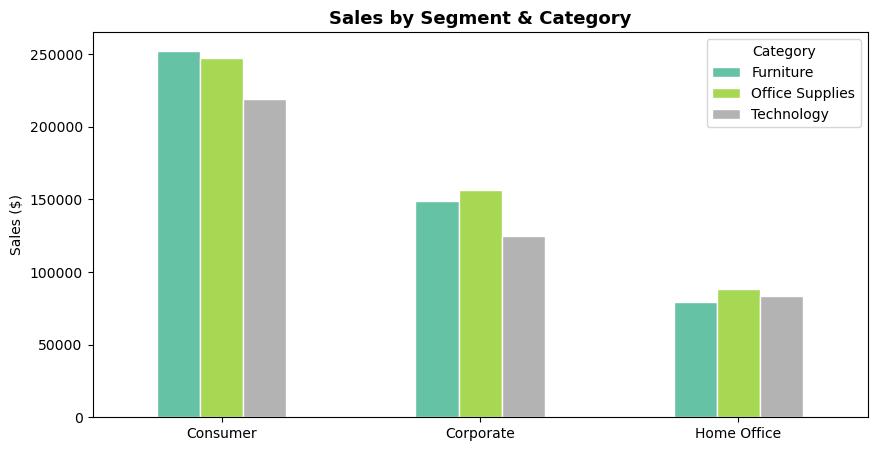

In [41]:
pivot2 = df.pivot_table(values='Sales', index='Segment', columns='Category', aggfunc='sum')

fig, ax = plt.subplots(figsize=(10, 5))
pivot2.plot(kind='bar', ax=ax, edgecolor='white', colormap='Set2')
ax.set_title('Sales by Segment & Category', fontsize=13, fontweight='bold')
ax.set_ylabel('Sales ($)')
ax.set_xlabel('')
ax.set_xticklabels(pivot2.index, rotation=0)
ax.legend(title='Category')
plt.show()

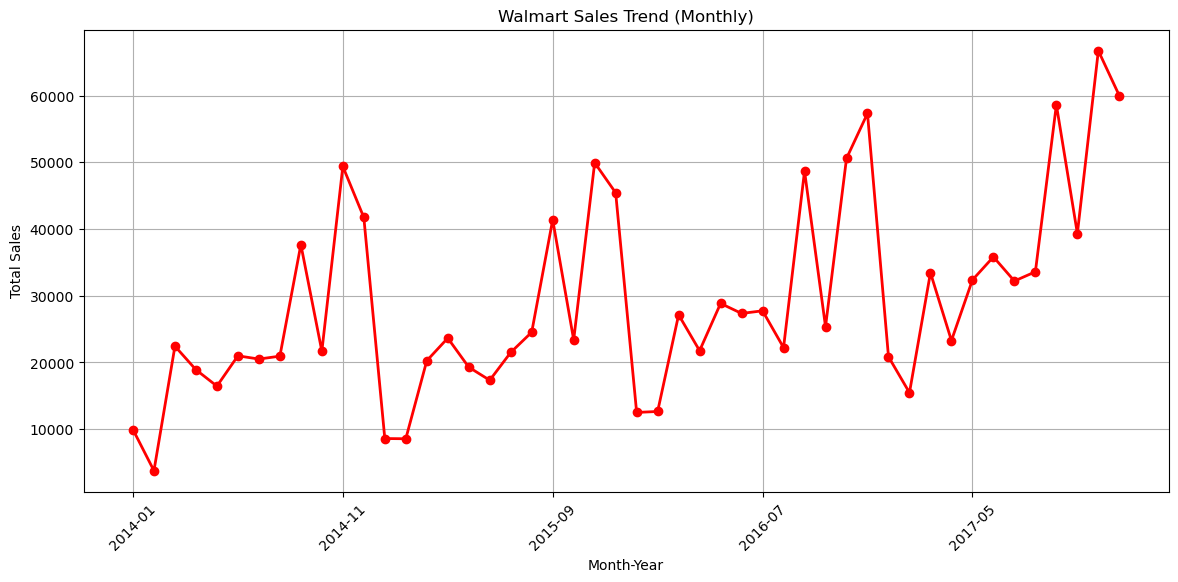

In [42]:
plt.figure(figsize=(14, 6))

trend_data = df.groupby('Month_Year')['Sales'].sum()
trend_data.plot(kind='line', marker='o', color='red', linewidth=2)
plt.title('Walmart Sales Trend (Monthly)')
plt.xlabel('Month-Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


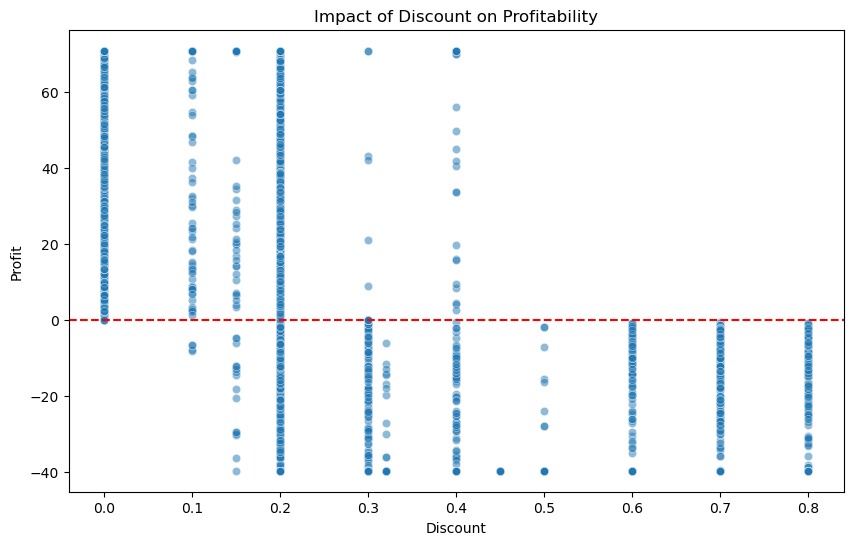

In [43]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Discount', y='Profit', data=df, alpha=0.5)
plt.title('Impact of Discount on Profitability')
plt.axhline(0, color='red', linestyle='--')
plt.show()


## 4. ALGORITHMS SECTION
### Feture Engneering & Encoding & Scaling

In [ ]:

cat_cols = ['Ship Mode', 'Segment', 'Country', 'City', 'State',
            'Region', 'Category', 'Sub-Category']
df_ml = df.copy()
le = LabelEncoder()
for col in cat_cols:
    df_ml[col] = le.fit_transform(df_ml[col])

df_ml['Order_Year'] = df_ml['Order Date'].dt.year
df_ml['Order_Month'] = df_ml['Order Date'].dt.month
df_ml['Order_Day'] = df_ml['Order Date'].dt.day
df_ml['Days_to_Ship'] = (df_ml['Ship Date'] - df_ml['Order Date']).dt.days

feature_cols = ['Quantity', 'Discount', 'Profit', 'Order_Year', 'Order_Month',
                'Order_Day', 'Days_to_Ship', 'Ship Mode', 'Segment',
                'Region', 'Category', 'Sub-Category']

X = df_ml[feature_cols]
y = df_ml['Sales']

X = X.fillna(X.mean(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

scaler = MinMaxScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=feature_cols, index=X_test.index)



---
## 5. REGRESSION


### 5 Linear Regression

In [45]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
y_train_pred_lr = lr_model.predict(X_train)

print('\n***** Linear Regression *****')
print(f'Training R²   : {r2_score(y_train, y_train_pred_lr):.4f}')
print(f'Test R²        : {r2_score(y_test, y_pred_lr):.4f}')
print(f'MAE            : {mean_absolute_error(y_test, y_pred_lr):.4f}')
print(f'RMSE           : {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f}')




***** Linear Regression *****
Training R²   : 0.2994
Test R²        : 0.2900
MAE            : 107.9019
RMSE           : 142.0285


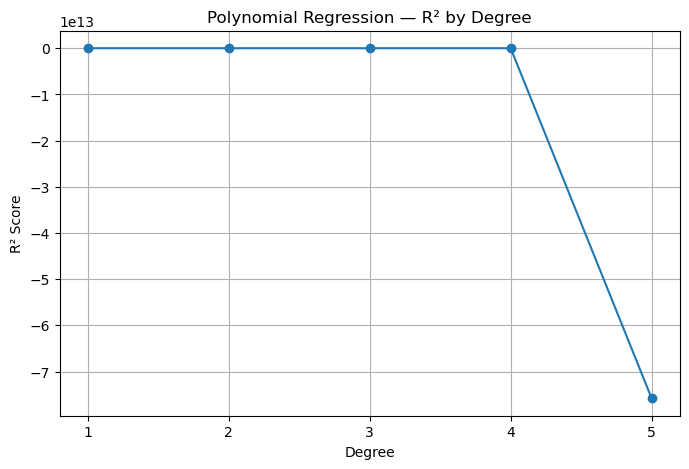


***** Best Polynomial Regression *****
Degree       : 3
Training R²  : 0.8033
Test R²      : 0.7887
MAE          : 50.7799
RMSE         : 77.4866


In [ ]:
degrees = range(1, 6)
poly_scores = []

best_score = -np.inf
best_degree = None
best_poly_model = None
best_poly = None

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_pred = model.predict(X_test_poly)
    score = r2_score(y_test, y_pred)
    poly_scores.append(score)

    # Save best model
    if score > best_score:
        best_score = score
        best_degree = d
        best_poly_model = model
        best_poly = poly

plt.figure(figsize=(8, 5))
plt.plot(degrees, poly_scores, marker='o')
plt.xlabel('Degree')
plt.ylabel('R² Score')
plt.title('Polynomial Regression — R² by Degree')
plt.xticks(degrees)
plt.grid(True)
plt.show()

X_train_best = best_poly.transform(X_train)
X_test_best = best_poly.transform(X_test)

y_train_pred = best_poly_model.predict(X_train_best)
y_test_pred = best_poly_model.predict(X_test_best)

print('\n***** Best Polynomial Regression *****')
print(f'Degree       : {best_degree}')
print(f'Training R²  : {r2_score(y_train, y_train_pred):.4f}')
print(f'Test R²      : {r2_score(y_test, y_test_pred):.4f}')
print(f'MAE          : {mean_absolute_error(y_test, y_test_pred):.4f}')
print(f'RMSE         : {np.sqrt(mean_squared_error(y_test, y_test_pred)):.4f}')

###  KNN

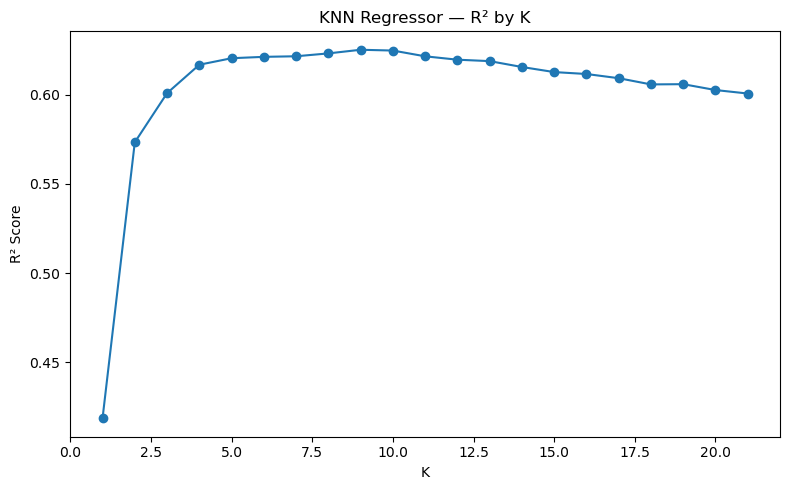

Best K: 9  →  R²: 0.6251

***** KNN Regressor *****
Training R²   : 0.6870
Test R²        : 0.6251
MAE            : 67.5000
RMSE           : 103.2061


In [47]:
knn_scores = []
k_range = range(1, 22)

for k in k_range:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    knn_scores.append(r2_score(y_test, knn.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(k_range, knn_scores, marker='o')
plt.xlabel('K')
plt.ylabel('R² Score')
plt.title('KNN Regressor — R² by K')
plt.tight_layout()
plt.show()

best_k = list(k_range)[np.argmax(knn_scores)]
print(f'Best K: {best_k}  →  R²: {max(knn_scores):.4f}')

knn_model = KNeighborsRegressor(n_neighbors=best_k)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print('\n***** KNN Regressor *****')
print(f'Training R²   : {r2_score(y_train, knn_model.predict(X_train)):.4f}')
print(f'Test R²        : {r2_score(y_test, y_pred_knn):.4f}')
print(f'MAE            : {mean_absolute_error(y_test, y_pred_knn):.4f}')
print(f'RMSE           : {np.sqrt(mean_squared_error(y_test, y_pred_knn)):.4f}')

### SVM

In [ ]:
svr_scores = []

C_range = [0.1, 1, 10, 50, 100, 200, 500]
epsilon_range = [0.001, 0.01, 0.1, 0.5, 1]

best_score = -np.inf
best_params = (None, None)

for C in C_range:
    for eps in epsilon_range:
        svr = SVR(kernel='rbf', C=C, epsilon=eps)
        svr.fit(X_train, y_train)
        
        score = r2_score(y_test, svr.predict(X_test))
        svr_scores.append((C, eps, score))
        
        if score > best_score:
            best_score = score
            best_params = (C, eps)

print(f'Best C: {best_params[0]}, Best epsilon: {best_params[1]} → R²: {best_score:.4f}')

Best C: 500, Best epsilon: 1 → R²: 0.7734


In [62]:
best_C, best_eps = best_params

svr_model = SVR(kernel='rbf', C=best_C, epsilon=best_eps)
svr_model.fit(X_train, y_train)

y_pred_svr = svr_model.predict(X_test)

print('\n***** Tuned SVR Model *****')
print(f'Training R²   : {r2_score(y_train, svr_model.predict(X_train)):.4f}')
print(f'Test R²        : {r2_score(y_test, y_pred_svr):.4f}')
print(f'MAE            : {mean_absolute_error(y_test, y_pred_svr):.4f}')
print(f'RMSE           : {np.sqrt(mean_squared_error(y_test, y_pred_svr)):.4f}')


***** Tuned SVR Model *****
Training R²   : 0.8023
Test R²        : 0.7734
MAE            : 46.3442
RMSE           : 80.2357


### Decision Tree

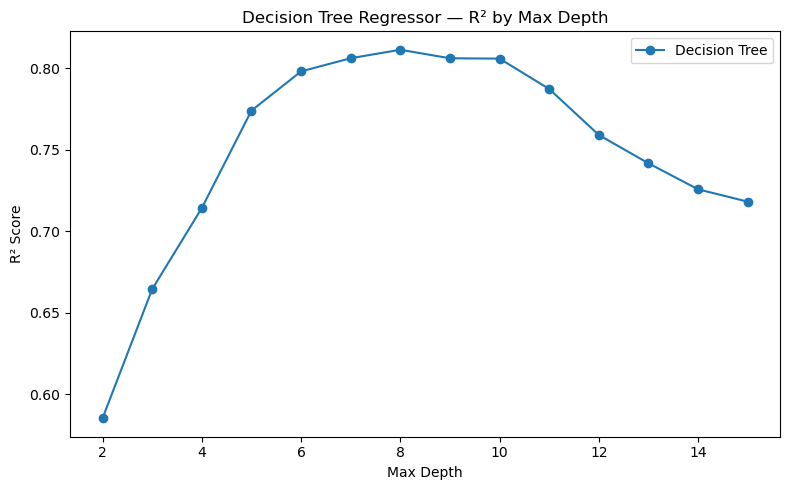

Best max_depth: 8  →  R²: 0.8112

***** Decision Tree Regressor *****
Training R²   : 0.8635
Test R²        : 0.8112
MAE            : 40.2800
RMSE           : 73.2305


In [48]:
acc_dt = []

for d in range(2, 16):
    dt = DecisionTreeRegressor(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    acc_dt.append(r2_score(y_test, dt.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 16), acc_dt, marker='o', label='Decision Tree')
plt.xlabel('Max Depth')
plt.ylabel('R² Score')
plt.title('Decision Tree Regressor — R² by Max Depth')
plt.legend()
plt.tight_layout()
plt.show()

best_depth = list(range(2, 16))[np.argmax(acc_dt)]
print(f'Best max_depth: {best_depth}  →  R²: {max(acc_dt):.4f}')

dt_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print('\n***** Decision Tree Regressor *****')
print(f'Training R²   : {r2_score(y_train, dt_model.predict(X_train)):.4f}')
print(f'Test R²        : {r2_score(y_test, y_pred_dt):.4f}')
print(f'MAE            : {mean_absolute_error(y_test, y_pred_dt):.4f}')
print(f'RMSE           : {np.sqrt(mean_squared_error(y_test, y_pred_dt)):.4f}')

### Random-Forst

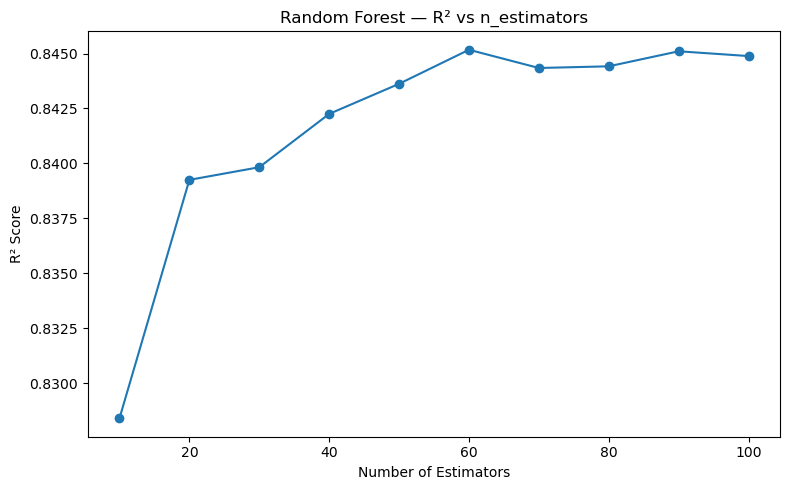

Best n_estimators: 60  →  R²: 0.8452

***** Random Forest Regressor *****
Training R²   : 0.9758
Test R²        : 0.8452
MAE            : 35.4669
RMSE           : 66.3236


In [49]:
rf_scores = []
estimator_range = range(10, 101, 10)

for n in estimator_range:
    rf = RandomForestRegressor(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)
    rf_scores.append(r2_score(y_test, rf.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(estimator_range, rf_scores, marker='o')
plt.xlabel('Number of Estimators')
plt.ylabel('R² Score')
plt.title('Random Forest — R² vs n_estimators')
plt.tight_layout()
plt.show()

best_n = list(estimator_range)[np.argmax(rf_scores)]
print(f'Best n_estimators: {best_n}  →  R²: {max(rf_scores):.4f}')

rf_model = RandomForestRegressor(n_estimators=best_n, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print('\n***** Random Forest Regressor *****')
print(f'Training R²   : {r2_score(y_train, rf_model.predict(X_train)):.4f}')
print(f'Test R²        : {r2_score(y_test, y_pred_rf):.4f}')
print(f'MAE            : {mean_absolute_error(y_test, y_pred_rf):.4f}')
print(f'RMSE           : {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}')




            Model       R²        MAE       RMSE
    Random Forest 0.845173  35.466947  66.323615
    Decision Tree 0.811246  40.280039  73.230517
       Polynomial 0.788669  50.779933  77.486579
              SVR 0.773407  46.344232  80.235750
              KNN 0.625094  67.499968 103.206148
Linear Regression 0.289994 107.901941 142.028547


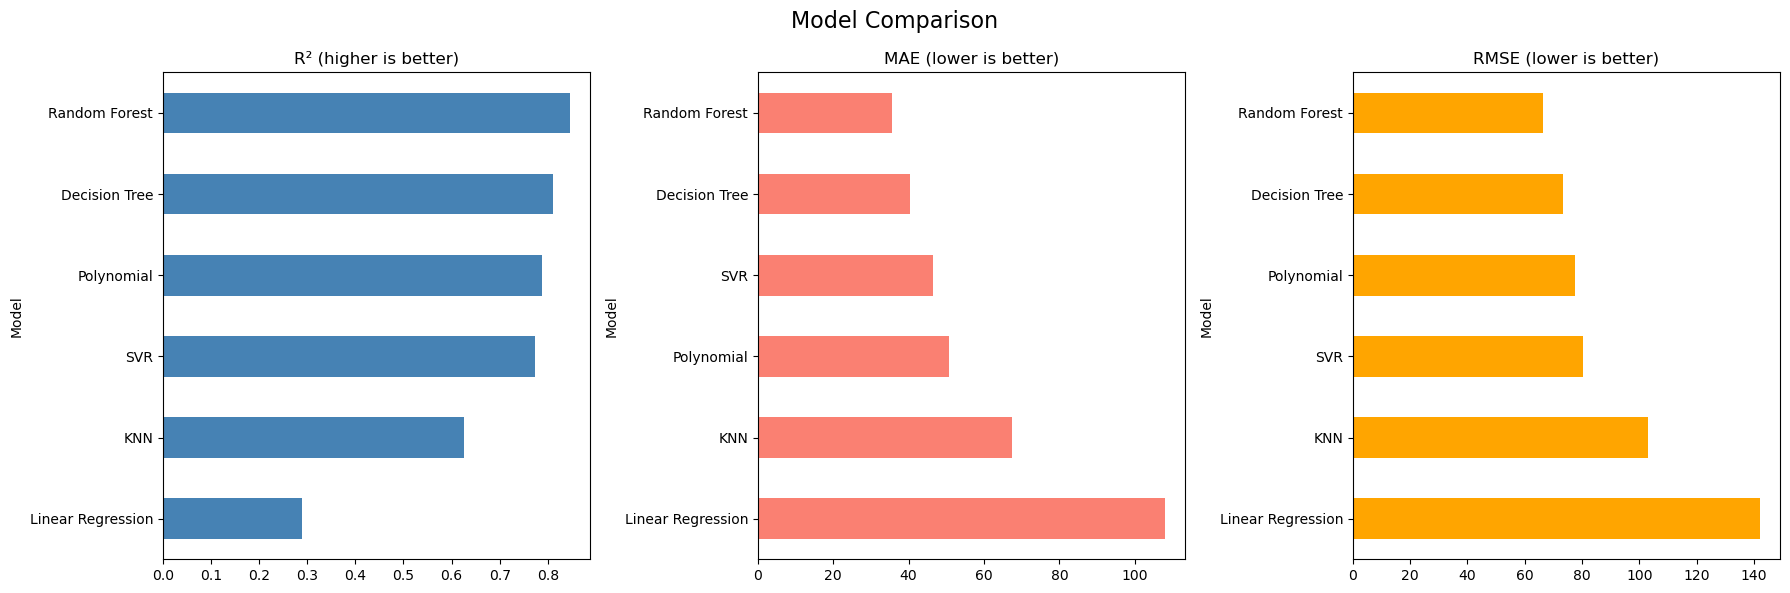

In [66]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial',  'KNN', 'SVR',
              'Decision Tree', 'Random Forest'],
    'R²': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_test_pred),
        r2_score(y_test, y_pred_knn),
        r2_score(y_test, y_pred_svr),
        r2_score(y_test, y_pred_dt),
        r2_score(y_test, y_pred_rf),
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_test_pred),
        mean_absolute_error(y_test, y_pred_knn),
        mean_absolute_error(y_test, y_pred_svr),
        mean_absolute_error(y_test, y_pred_dt),
        mean_absolute_error(y_test, y_pred_rf),
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        np.sqrt(mean_squared_error(y_test, y_pred_knn)),
        np.sqrt(mean_squared_error(y_test, y_pred_svr)),
        np.sqrt(mean_squared_error(y_test, y_pred_dt)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    ]
}).sort_values('R²', ascending=False).reset_index(drop=True)

print(results.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

results.sort_values('R²').plot(
    x='Model', y='R²', kind='barh', ax=axes[0], legend=False, color='steelblue'
)
results.sort_values('MAE', ascending=False).plot(
    x='Model', y='MAE', kind='barh', ax=axes[1], legend=False, color='salmon'
)
results.sort_values('RMSE', ascending=False).plot(
    x='Model', y='RMSE', kind='barh', ax=axes[2], legend=False, color='orange'
)

axes[0].set_title('R² (higher is better)')
axes[1].set_title('MAE (lower is better)')
axes[2].set_title('RMSE (lower is better)')

plt.suptitle('Model Comparison', fontsize=16)
plt.tight_layout()
plt.show()

---
## 7. CLUSTERING


### 7.1 K-Means

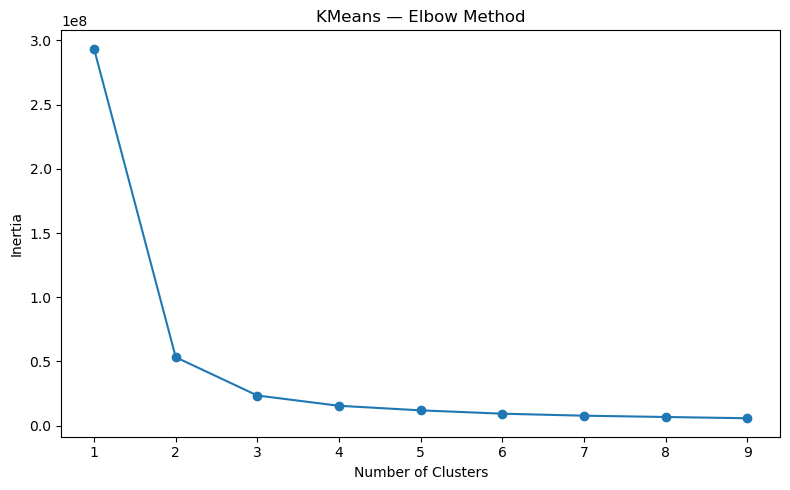

KMeans Cluster Distribution:
KMeans_Cluster
0    6485
2    1926
3     899
1     684
Name: count, dtype: int64

Cluster Mean Profiles:
                 Sales  Profit  Quantity  Discount
KMeans_Cluster                                    
0                52.97   11.60      3.44      0.09
1               396.43  -29.93      4.34      0.31
2               392.78   62.87      4.82      0.07
3                34.27  -16.99      3.71      0.69


In [78]:
cluster_features = ['Sales', 'Profit', 'Quantity', 'Discount']

X_cluster = df_ml[cluster_features].copy()
X_cluster = X_cluster.fillna(X_cluster.median(numeric_only=True))

X_cluster_scaled = MinMaxScaler().fit_transform(X_cluster)

inertia = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 10), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('KMeans — Elbow Method')
plt.tight_layout()
plt.show()

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_cluster_scaled)
df_ml['KMeans_Cluster'] = kmeans_labels

print('KMeans Cluster Distribution:')
print(df_ml['KMeans_Cluster'].value_counts())



print('\nCluster Mean Profiles:')
print(df_ml.groupby('KMeans_Cluster')[cluster_features].mean().round(2))

# Time Series

In [53]:
ts = (
    df.groupby(df['Order Date'].dt.to_period('M'))['Sales']
    .sum()
    .reset_index()
)
ts['Order Date'] = ts['Order Date'].dt.to_timestamp()
ts = ts.set_index('Order Date')
ts.index.freq = 'MS'

print('Monthly Time Series:')
print(f'\nTotal months : {len(ts)}')
print(f'Date range   : {ts.index.min().date()} → {ts.index.max().date()}')
min_sales = ts['Sales'].min()
max_sales = ts['Sales'].max()
min_date = ts['Sales'].idxmin()
max_date = ts['Sales'].idxmax()
print(f'\nMin Sales    : ${min_sales:,.2f} at {min_date.date()}')
print(f'Max Sales    : ${max_sales:,.2f} at {max_date.date()}')

Monthly Time Series:

Total months : 48
Date range   : 2014-01-01 → 2017-12-01

Min Sales    : $3,762.60 at 2014-02-01
Max Sales    : $66,727.76 at 2017-11-01


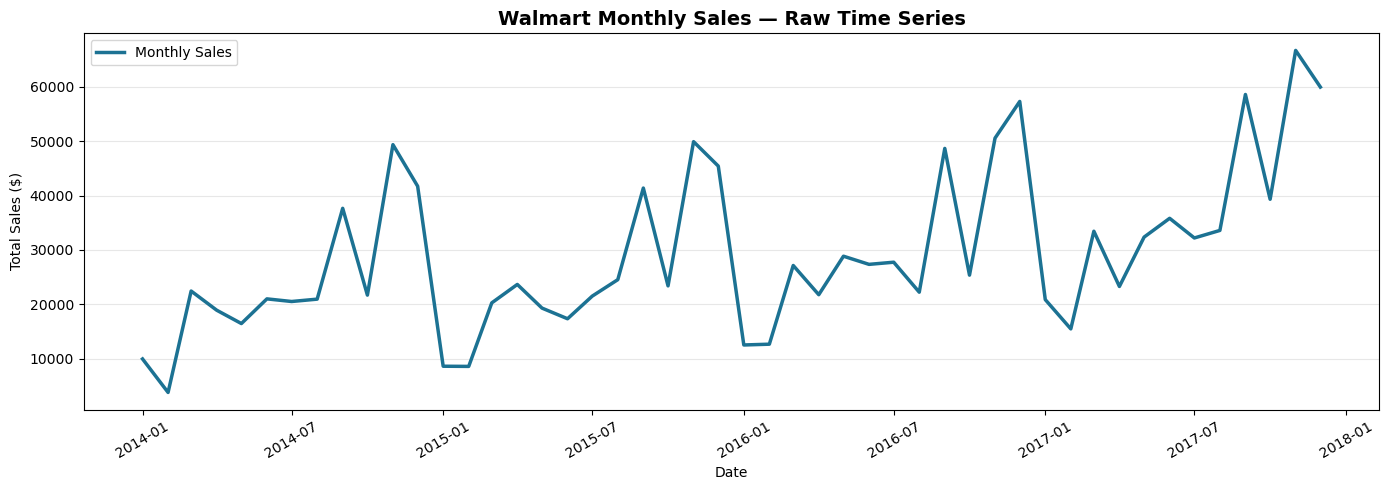

In [54]:
plt.figure(figsize=(14, 5))
plt.plot(ts.index, ts['Sales'], color='#1C7293', linewidth=2.5, label='Monthly Sales')
plt.title('Walmart Monthly Sales — Raw Time Series', fontsize=14, fontweight='bold')
plt.xlabel('Date'); plt.ylabel('Total Sales ($)')
plt.xticks(rotation=30); plt.grid(axis='y', alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

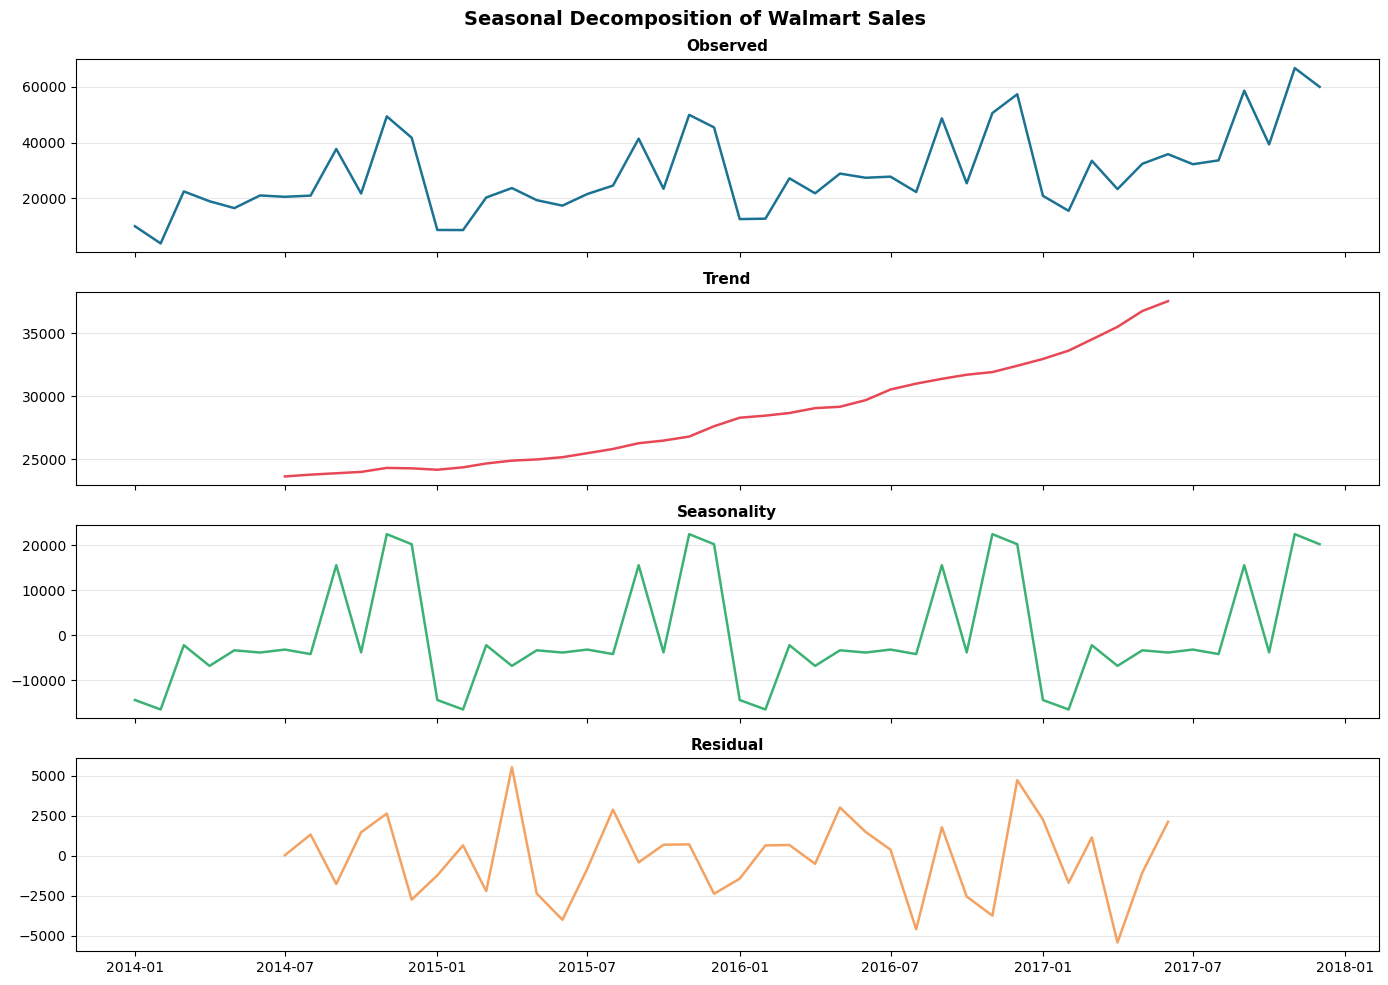

In [55]:
decomp = seasonal_decompose(ts['Sales'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, data, title, color in zip(
    axes,
    [ts['Sales'], decomp.trend, decomp.seasonal, decomp.resid],
    ['Observed', 'Trend', 'Seasonality', 'Residual'],
    ['#1C7293', '#E84855', '#3BB273', '#F4A261']
):
    ax.plot(data, color=color, linewidth=1.8)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle('Seasonal Decomposition of Walmart Sales', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

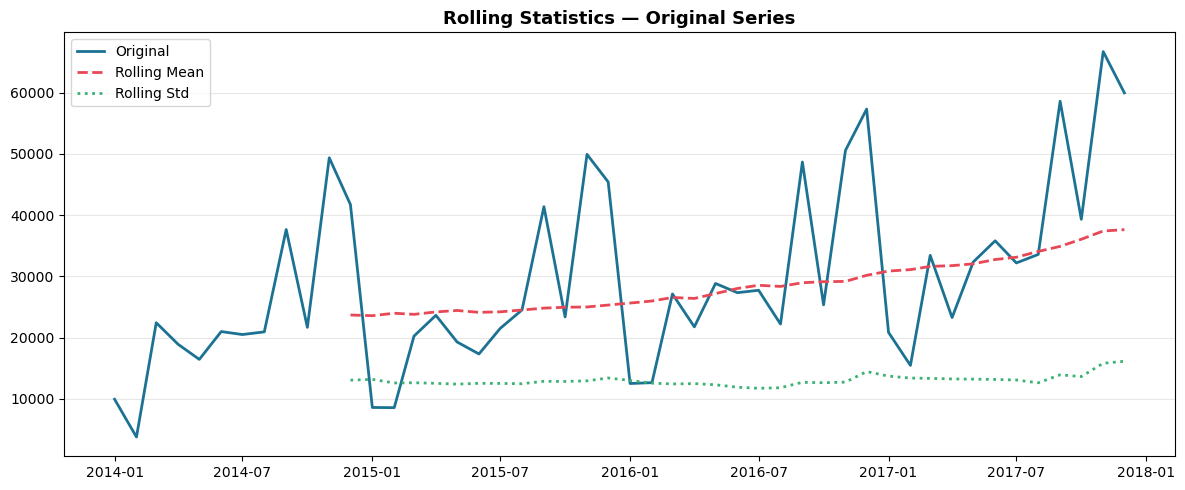


── ADF Test: Original Series ──
  ADF Statistic : -4.0883
  p-value       : 0.0010   Stationary
  Critical Values:
    1%: -3.5778
    5%: -2.9253
    10%: -2.6008


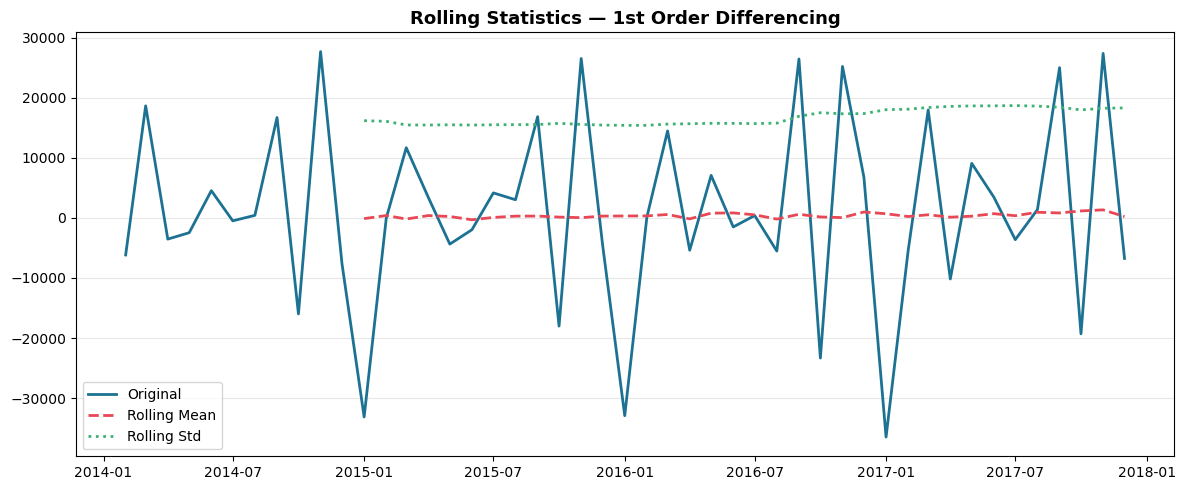


── ADF Test: 1st Order Differencing ──
  ADF Statistic : -15.3926
  p-value       : 0.0000   Stationary
  Critical Values:
    1%: -3.6267
    5%: -2.9460
    10%: -2.6117


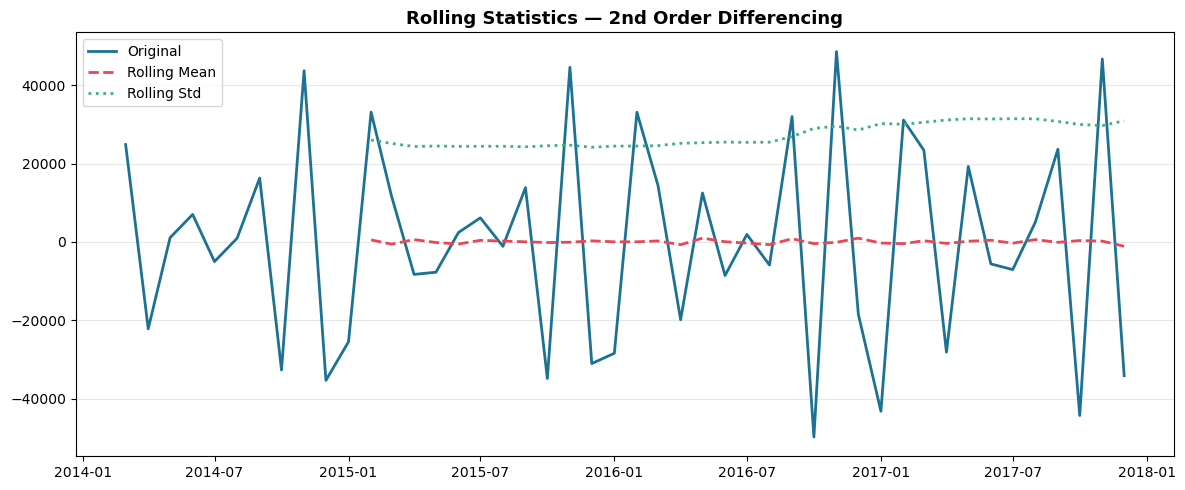


── ADF Test: 2nd Order Differencing ──
  ADF Statistic : -9.1674
  p-value       : 0.0000   Stationary
  Critical Values:
    1%: -3.6327
    5%: -2.9485
    10%: -2.6130


In [56]:
def check_stationarity(series, title='Series'):
    roll_mean = series.rolling(window=12).mean()
    roll_std  = series.rolling(window=12).std()

    plt.figure(figsize=(12, 5))
    plt.plot(series,    color='#1C7293', label='Original',     linewidth=2)
    plt.plot(roll_mean, color='#E84855', label='Rolling Mean', linewidth=2, linestyle='--')
    plt.plot(roll_std,  color='#3BB273', label='Rolling Std',  linewidth=2, linestyle=':')
    plt.title(f'Rolling Statistics — {title}', fontsize=13, fontweight='bold')
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    result = adfuller(series.dropna())
    print(f"\n── ADF Test: {title} ──")
    print(f"  ADF Statistic : {result[0]:.4f}")
    print(f"  p-value       : {result[1]:.4f}  {' Stationary' if result[1] < 0.05 else ' NOT Stationary'}")
    print("  Critical Values:")
    for key, val in result[4].items():
        print(f"    {key}: {val:.4f}")

check_stationarity(ts['Sales'],                    'Original Series')
check_stationarity(ts['Sales'].diff().dropna(),    '1st Order Differencing')
check_stationarity(ts['Sales'].diff().diff().dropna(), '2nd Order Differencing')


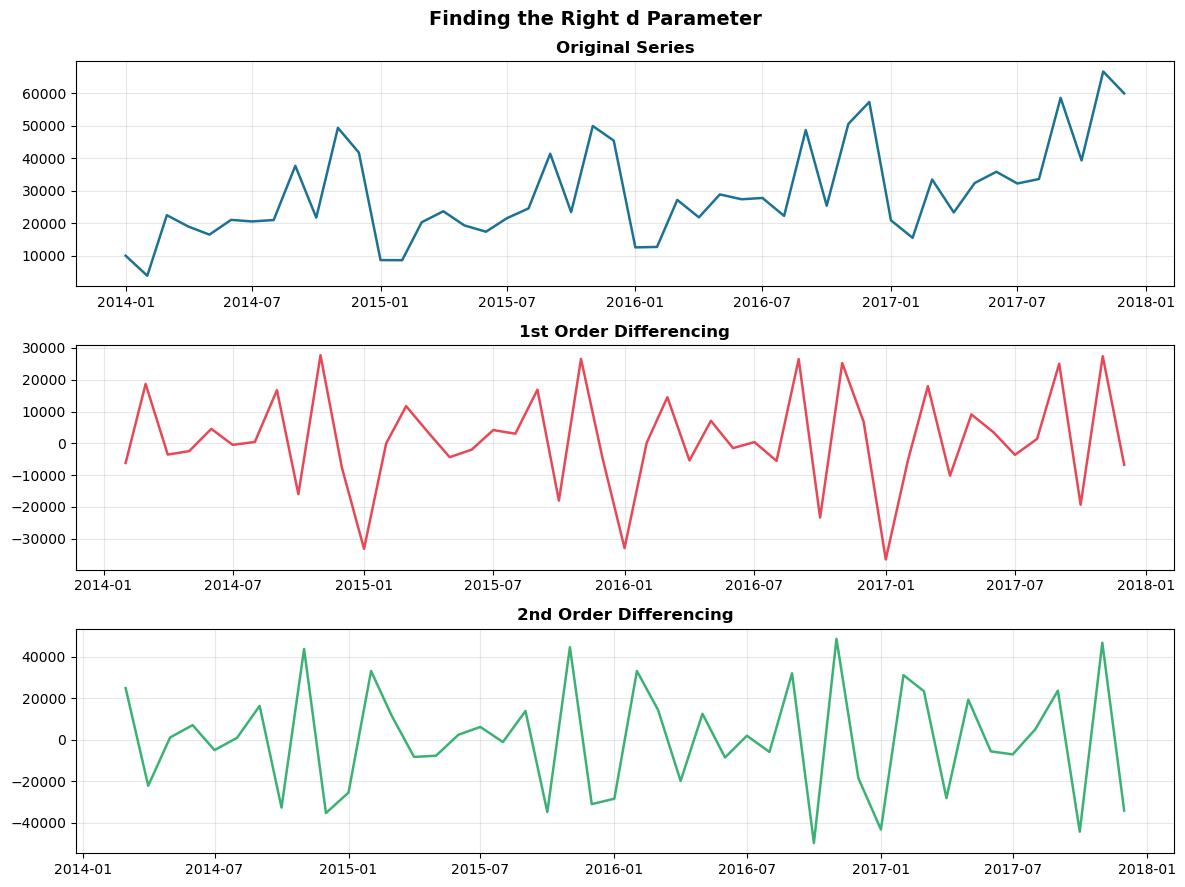

In [57]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 9))

ax1.plot(ts['Sales'],              color='#1C7293', linewidth=1.8)
ax1.set_title('Original Series',          fontweight='bold'); ax1.grid(alpha=0.3)

ax2.plot(ts['Sales'].diff(),       color='#E84855', linewidth=1.8)
ax2.set_title('1st Order Differencing',   fontweight='bold'); ax2.grid(alpha=0.3)

ax3.plot(ts['Sales'].diff().diff(),color='#3BB273', linewidth=1.8)
ax3.set_title('2nd Order Differencing',   fontweight='bold'); ax3.grid(alpha=0.3)

plt.suptitle('Finding the Right d Parameter', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

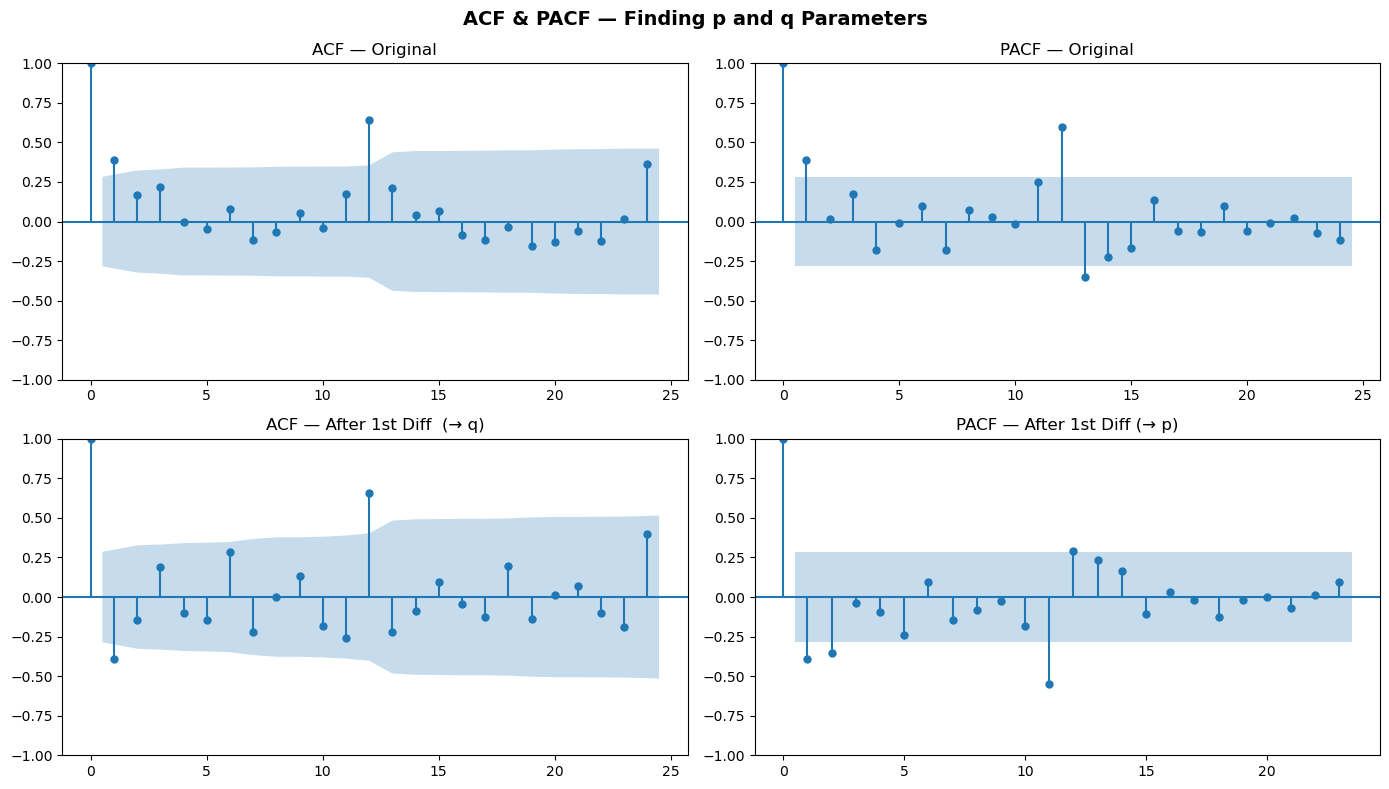

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf( ts['Sales'],                  ax=axes[0,0], lags=24, title='ACF — Original')
plot_pacf(ts['Sales'],                  ax=axes[0,1], lags=24, title='PACF — Original')
plot_acf( ts['Sales'].diff().dropna(),  ax=axes[1,0], lags=24, title='ACF — After 1st Diff  (→ q)')
plot_pacf(ts['Sales'].diff().dropna(),  ax=axes[1,1], lags=23, title='PACF — After 1st Diff (→ p)')

plt.suptitle('ACF & PACF — Finding p and q Parameters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

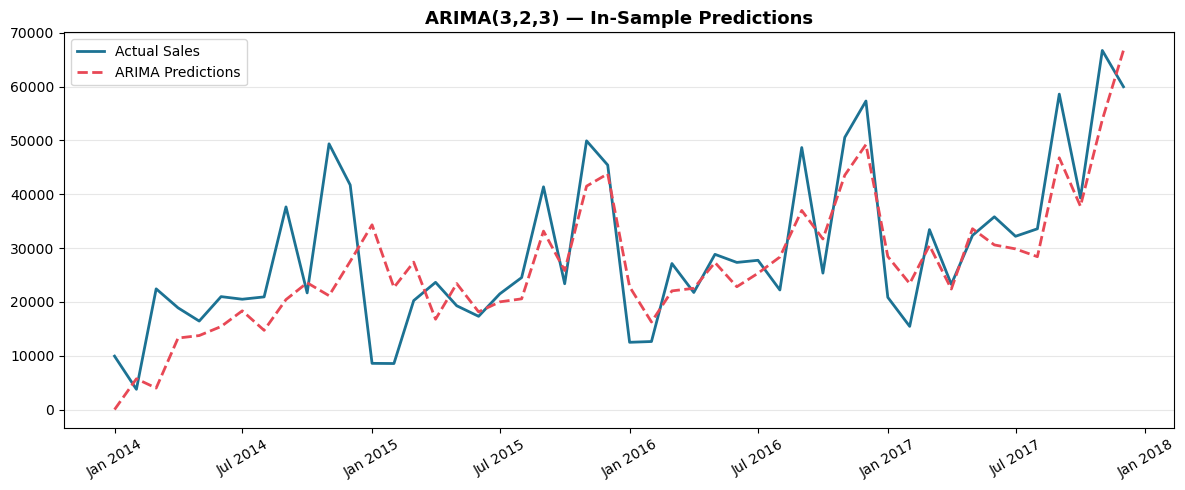

In [83]:
model       = ARIMA(ts['Sales'], order=(12, 1, 12))
# model       = ARIMA(ts['Sales'], order=(5, 1, 2))
#(P,D,Q)
arima_model = model.fit()
predict = arima_model.predict()

plt.figure(figsize=(12, 5))
plt.plot(ts.index, ts['Sales'], color='#1C7293', linewidth=2,   label='Actual Sales')
plt.plot(ts.index, predict,      color='#E84855', linewidth=2, linestyle='--',  label='ARIMA Predictions')
plt.title('ARIMA(3,2,3) — In-Sample Predictions', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

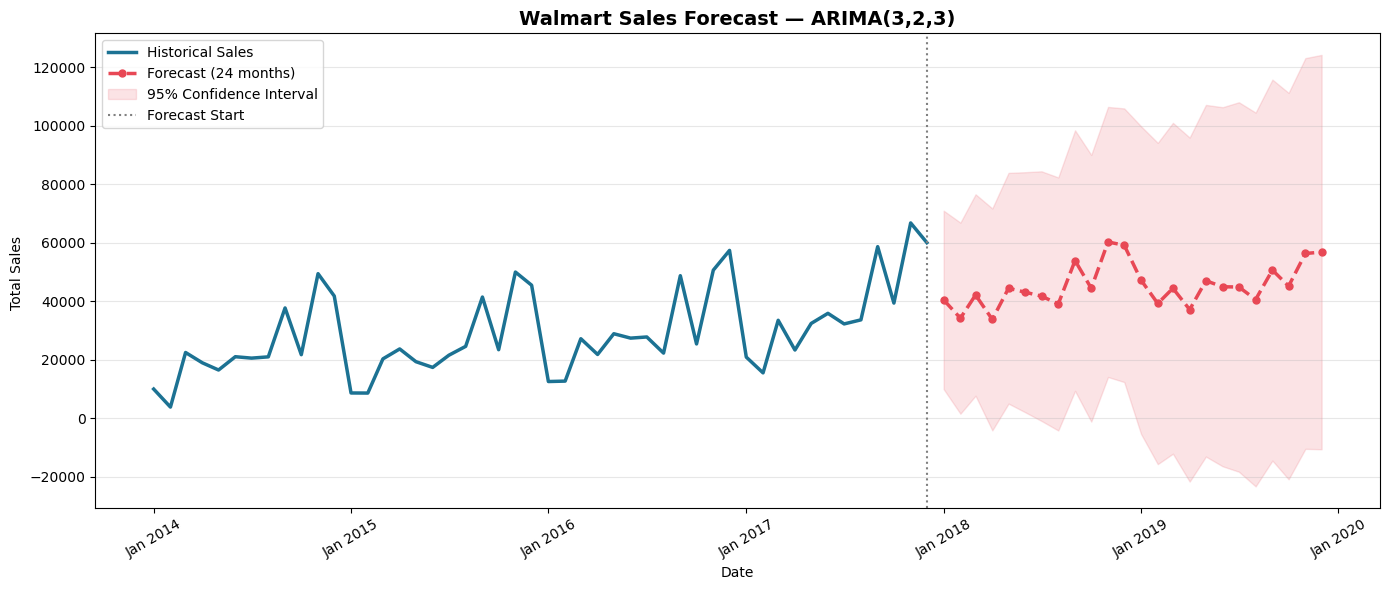

   Month  Forecasted Sales
Jan 2018          40412.17
Feb 2018          34171.09
Mar 2018          42086.44
Apr 2018          33735.23
May 2018          44394.15
Jun 2018          43030.17
Jul 2018          41703.35
Aug 2018          39025.40
Sep 2018          53853.58
Oct 2018          44392.65
Nov 2018          60220.69
Dec 2018          59100.83
Jan 2019          47197.47
Feb 2019          39185.33
Mar 2019          44384.36
Apr 2019          37101.81
May 2019          46960.91
Jun 2019          44902.69
Jul 2019          44826.07
Aug 2019          40549.94
Sep 2019          50603.96
Oct 2019          45133.70
Nov 2019          56281.60
Dec 2019          56759.93


In [84]:
forecast_steps  = 24
forecast_result = arima_model.get_forecast(steps=forecast_steps)
forecast_mean   = forecast_result.predicted_mean
conf_int        = forecast_result.conf_int()
forecast_index  = pd.date_range(
    start=ts.index[-1] + pd.DateOffset(months=1),
    periods=forecast_steps, freq='MS'
)

plt.figure(figsize=(14, 6))
plt.plot(ts.index,       ts['Sales'],           color='#1C7293', linewidth=2.5, label='Historical Sales')
plt.plot(forecast_index, forecast_mean.values,  color='#E84855', linewidth=2.5, linestyle='--', marker='o', markersize=5, label='Forecast (24 months)')
plt.fill_between(forecast_index, conf_int.iloc[:, 0].values,conf_int.iloc[:, 1].values, color='#E84855', alpha=0.15, label='95% Confidence Interval')
plt.axvline(ts.index[-1], color='gray', linestyle=':', linewidth=1.5, label='Forecast Start')
plt.title('Walmart Sales Forecast — ARIMA(3,2,3)', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Sales ')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=30)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

forecast_df = pd.DataFrame({
    'Month':              forecast_index.strftime('%b %Y'),
    'Forecasted Sales':   forecast_mean.values.round(2)
})
print(forecast_df.to_string(index=False))